In [1]:
pip install numpy matplotlib

Iteration: 0 Best Cost: 9.7001
Iteration: 100 Best Cost: 7.2446
Iteration: 200 Best Cost: 7.2432
Iteration: 300 Best Cost: 7.2341
Iteration: 400 Best Cost: 7.2341
Iteration: 500 Best Cost: 7.233
Iteration: 600 Best Cost: 7.233
Iteration: 700 Best Cost: 7.233
Iteration: 800 Best Cost: 7.2326
Iteration: 900 Best Cost: 7.2311

========== FINAL RESULTS ==========
Best Path Coordinates:
[0. 0.]
[0.224 0.291]
[0.859 1.135]
[2.771 3.697]
[4. 6.]

Optimal Path Distance: 7.2307
Obstacle Violation: 0.0
Best Fitness: 7.2307


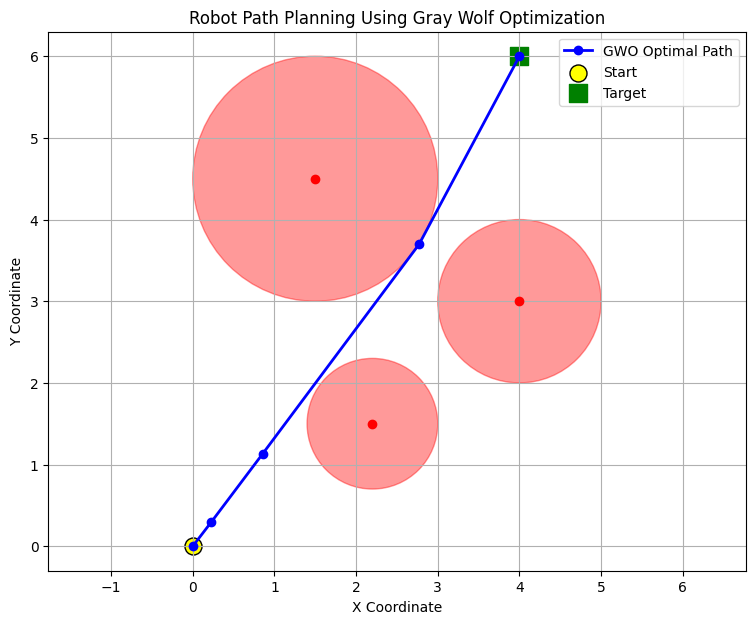

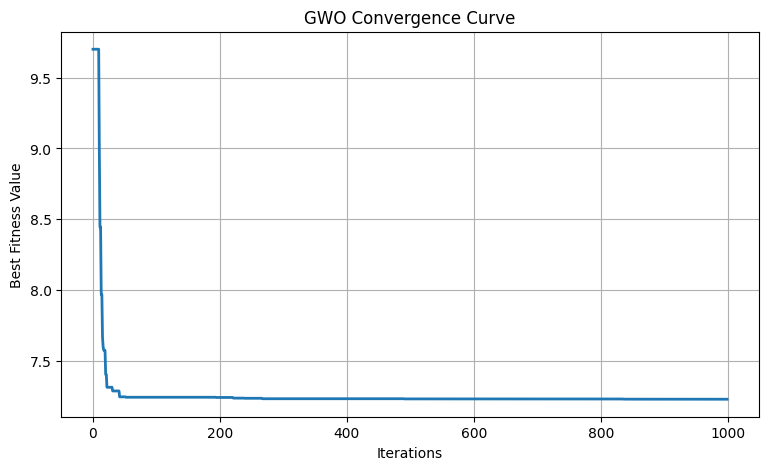

In [2]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. ROBOT PATH PLANNING USING GWO
# ==========================================

np.random.seed(42)

# Start and target positions
start = np.array([0.0, 0.0])
goal = np.array([4.0, 6.0])

# Three circular obstacles (center_x, center_y, radius)
obstacles = [
    (2.2, 1.5, 0.8),
    (4.0, 3.0, 1.0),
    (1.5, 4.5, 1.5)
]

# GWO parameters
population_size = 50
max_iterations = 1000
number_of_points = 3
dimension = number_of_points * 2

beta = 100
lower_bound = 0.0
upper_bound = 6.0


# ==========================================
# 2. GENERATE ROBOT PATH
# ==========================================

def get_path(wolf):

    points = wolf.reshape(number_of_points, 2)

    return np.vstack((start, points, goal))


# ==========================================
# 3. CALCULATE PATH DISTANCE
# ==========================================

def calculate_distance(path):

    distance = 0

    for i in range(len(path) - 1):

        distance += np.linalg.norm(
            path[i + 1] - path[i]
        )

    return distance


# ==========================================
# 4. OBSTACLE VIOLATION CALCULATION
# ==========================================

def calculate_violation(path):

    violation = 0.0

    # Sample points along each path segment
    samples = []

    for i in range(len(path) - 1):

        for t in np.linspace(0, 1, 20):
            point = (
                path[i] * (1 - t)
                + path[i + 1] * t
            )
            samples.append(point)

    samples = np.array(samples)

    for ox, oy, radius in obstacles:

        center = np.array([ox, oy])

        distances = np.linalg.norm(
            samples - center,
            axis=1
        )

        a = np.maximum(
            1 - distances / radius,
            0
        )

        violation += np.mean(a)

    return violation


# ==========================================
# 5. FITNESS FUNCTION
# ==========================================

def fitness(wolf):

    path = get_path(wolf)

    distance = calculate_distance(path)

    violation = calculate_violation(path)

    # Paper's objective function:
    # J = Q * (1 + beta * V)

    cost = distance * (1 + beta * violation)

    return cost


# ==========================================
# 6. INITIALIZE GRAY WOLVES
# ==========================================

wolves = np.random.uniform(
    lower_bound,
    upper_bound,
    (population_size, dimension)
)

alpha_position = None
beta_position = None
delta_position = None

alpha_score = float("inf")
beta_score = float("inf")
delta_score = float("inf")

convergence = []


# ==========================================
# 7. GRAY WOLF OPTIMIZATION
# ==========================================

for iteration in range(max_iterations):

    # Evaluate all wolves
    for i in range(population_size):

        score = fitness(wolves[i])

        if score < alpha_score:

            delta_score = beta_score
            delta_position = (
                beta_position.copy()
                if beta_position is not None else None
            )

            beta_score = alpha_score
            beta_position = (
                alpha_position.copy()
                if alpha_position is not None else None
            )

            alpha_score = score
            alpha_position = wolves[i].copy()

        elif score < beta_score:

            delta_score = beta_score
            delta_position = (
                beta_position.copy()
                if beta_position is not None else None
            )

            beta_score = score
            beta_position = wolves[i].copy()

        elif score < delta_score:

            delta_score = score
            delta_position = wolves[i].copy()

    # Decrease parameter from 2 to 0
    a = 2 - iteration * (2 / max_iterations)

    # Update wolf positions
    for i in range(population_size):

        new_positions = []

        leaders = [
            alpha_position,
            beta_position,
            delta_position
        ]

        for leader in leaders:

            r1 = np.random.random(dimension)
            r2 = np.random.random(dimension)

            A = 2 * a * r1 - a
            C = 2 * r2

            D = np.abs(
                C * leader - wolves[i]
            )

            X = leader - A * D

            new_positions.append(X)

        # Average position of alpha, beta and delta
        wolves[i] = np.mean(
            new_positions,
            axis=0
        )

        wolves[i] = np.clip(
            wolves[i],
            lower_bound,
            upper_bound
        )

    convergence.append(alpha_score)

    if iteration % 100 == 0:

        print(
            "Iteration:",
            iteration,
            "Best Cost:",
            round(alpha_score, 4)
        )


# ==========================================
# 8. FINAL OPTIMAL PATH
# ==========================================

best_path = get_path(alpha_position)

best_distance = calculate_distance(best_path)

best_violation = calculate_violation(best_path)

print("\n========== FINAL RESULTS ==========")

print("Best Path Coordinates:")

for point in best_path:
    print(np.round(point, 3))

print("\nOptimal Path Distance:",
      round(best_distance, 4))

print("Obstacle Violation:",
      round(best_violation, 6))

print("Best Fitness:",
      round(alpha_score, 4))


# ==========================================
# 9. DRAW ROBOT PATH AND OBSTACLES
# ==========================================

plt.figure(figsize=(9, 7))

# Draw circular obstacles
for ox, oy, radius in obstacles:

    circle = plt.Circle(
        (ox, oy),
        radius,
        color="red",
        alpha=0.4
    )

    plt.gca().add_patch(circle)

    plt.plot(
        ox,
        oy,
        "ro"
    )

# Draw optimal path
plt.plot(
    best_path[:, 0],
    best_path[:, 1],
    "b-o",
    linewidth=2,
    label="GWO Optimal Path"
)

# Start and goal
plt.scatter(
    start[0],
    start[1],
    color="yellow",
    edgecolors="black",
    s=150,
    label="Start"
)

plt.scatter(
    goal[0],
    goal[1],
    color="green",
    marker="s",
    s=150,
    label="Target"
)

plt.xlim(-1, 6)
plt.ylim(0, 6)

plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")

plt.title("Robot Path Planning Using Gray Wolf Optimization")

plt.grid(True)
plt.legend()
plt.axis("equal")
plt.show()


# ==========================================
# 10. CONVERGENCE GRAPH
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    convergence,
    linewidth=2
)

plt.xlabel("Iterations")
plt.ylabel("Best Fitness Value")

plt.title("GWO Convergence Curve")

plt.grid(True)
plt.show()
